# Tarification : du diagnostic à un tarif

Le premier notebook ([validation_statistique.ipynb](validation_statistique.ipynb)) a établi **qui** coûte le plus cher et **pourquoi**.
Celui-ci construit un **tarif** : le prix qu'il faudrait facturer à chaque profil pour couvrir ses sinistres.

En assurance, la prime pure se décompose en deux parties, modélisées séparément :

$$\text{Prime pure} = \underbrace{\text{Fréquence}}_{\text{GLM de Poisson}} \times \underbrace{\text{Coût moyen d'un sinistre}}_{\text{GLM Gamma}} \times \underbrace{(1 + \text{chargement sinistres graves})}_{\text{mutualisé}}$$

- **La fréquence** (combien d'accidents par an) est un comptage : on utilise un GLM de **Poisson**.
- **Le coût d'un sinistre** est un montant positif et très asymétrique : on utilise un GLM **Gamma**. Il est estimé sur les sinistres **écrêtés** à 34 495 €.
- **Les sinistres graves** au-delà de ce seuil sont imprévisibles et rares. Leur surcoût est réparti sur tous les assurés par un **chargement** commun.

**Méthode de validation.** Les contrats sont tirés au hasard : 80 % servent à construire le tarif, et 20 % sont mis de côté pour le tester sur des données qu'il n'a jamais vues.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

DATA, FIG = Path("../data"), Path("../docs/figures")
BLEU, ORANGE, VERT, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a8a"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Données et échantillons

In [2]:
freq = pd.read_csv(DATA / "freMTPL2freq.csv", usecols=lambda c: not c.startswith("Unnamed") and c not in ("", "ClaimNb", "ClaimTotal"))
sev = pd.read_csv(DATA / "freMTPL2sev.csv")
sev = sev[sev["IDpol"].isin(freq["IDpol"])].copy()          # sinistres rattachés à un contrat
freq["Exposure"] = freq["Exposure"].clip(upper=1)

AGE = ["Expérimenté (41-60)", "Jeune (18-25)", "Confirmé (26-40)", "Senior (61+)"]            # 1er = référence
PUI = ["Faible (4-6)", "Moyenne (7-9)", "Élevée (10+)"]
BM = ["Bonus fort (50-79)", "Bonus léger (80-99)", "Neutre (100)", "Malus (101-150)", "Malus fort (>150)"]
freq["age"] = pd.cut(freq["DrivAge"], [17, 25, 40, 60, 200], labels=["Jeune (18-25)", "Confirmé (26-40)", "Expérimenté (41-60)", "Senior (61+)"])
freq["puissance"] = pd.cut(freq["VehPower"], [0, 6, 9, 99], labels=PUI)
freq["bm"] = pd.cut(freq["BonusMalus"], [0, 79, 99, 100, 150, 999], labels=BM)
for col, cats in [("age", AGE), ("puissance", PUI), ("bm", BM)]:
    freq[col] = pd.Categorical(freq[col].astype(str), categories=cats)

SEUIL = sev["ClaimAmount"].quantile(0.995)
sev["ecrete"] = sev["ClaimAmount"].clip(upper=SEUIL)
par_contrat = sev.groupby("IDpol").agg(nb=("ClaimAmount", "size"), cout=("ClaimAmount", "sum"), cout_ecrete=("ecrete", "sum"))
df = freq.join(par_contrat, on="IDpol").fillna({"nb": 0, "cout": 0, "cout_ecrete": 0})

rng = np.random.default_rng(2026)
df["apprentissage"] = rng.random(len(df)) < 0.8
sev = sev.merge(df[["IDpol", "age", "puissance", "bm", "apprentissage"]], on="IDpol")
app, test = df[df["apprentissage"]], df[~df["apprentissage"]]
print(f"Seuil d'écrêtement : {SEUIL:,.0f} €")
print(f"Apprentissage : {len(app):,} contrats, {app['nb'].sum():,.0f} sinistres | Test : {len(test):,} contrats, {test['nb'].sum():,.0f} sinistres")

Seuil d'écrêtement : 34,495 €
Apprentissage : 542,841 contrats, 21,188 sinistres | Test : 135,166 contrats, 5,195 sinistres


## 2. Modèle de fréquence (GLM de Poisson)

Même modèle que dans le premier notebook, mais estimé **uniquement sur l'échantillon d'apprentissage**.
Je compare deux versions sur l'échantillon test : avec ou sans l'interaction âge × puissance.
La meilleure est celle qui a la plus petite **déviance de Poisson** sur des données jamais vues.

In [3]:
def agreger(d):
    return d.groupby(["age", "puissance", "bm"], observed=True).agg(n=("nb", "sum"), expo=("Exposure", "sum")).reset_index()

cases_app = agreger(app)
FORMULES_FREQ = {"sans interaction": "n ~ age + puissance + bm", "avec interaction âge × puissance": "n ~ age * puissance + bm"}
freq_glm = {k: smf.glm(f, cases_app, family=sm.families.Poisson(), offset=np.log(cases_app["expo"])).fit()
            for k, f in FORMULES_FREQ.items()}

def deviance_poisson(y, mu):
    y, mu = np.asarray(y, float), np.asarray(mu, float)
    return 2 * np.sum(np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / mu), 0) - (y - mu))

cases_test = agreger(test)
comparaison = pd.DataFrame({k: {"AIC (apprentissage)": m.aic,
                                "déviance (test)": deviance_poisson(cases_test["n"], m.predict(cases_test, offset=np.log(cases_test["expo"])))}
                            for k, m in freq_glm.items()}).T
comparaison

,AIC (apprentissage),déviance (test)
sans interaction,518.103,75.490
avec interaction âge × puissance,507.850,60.842


In [4]:
choix_freq = comparaison["déviance (test)"].idxmin()
m_freq = freq_glm[choix_freq]
print("Modèle de fréquence retenu :", choix_freq)

Modèle de fréquence retenu : avec interaction âge × puissance


## 3. Modèle de coût d'un sinistre (GLM Gamma)

Chaque ligne est un sinistre, écrêté au seuil. La loi Gamma convient aux montants positifs et asymétriques, et le lien logarithmique donne, comme pour la fréquence, des effets **multiplicatifs**.
J'estime d'abord un modèle complet, puis je ne garde que les variables qui ont un effet significatif. Un tarif plus simple est plus robuste et plus facile à expliquer.

In [5]:
sev_app = sev[sev["apprentissage"]]
GAMMA = sm.families.Gamma(sm.families.links.Log())

def tableau_relativites(m):
    ci = m.conf_int()
    t = pd.DataFrame({"relativité": np.exp(m.params), "IC bas": np.exp(ci[0]), "IC haut": np.exp(ci[1]), "p-valeur": m.pvalues})
    return t.drop("Intercept")

m_cout_complet = smf.glm("ecrete ~ age + puissance + bm", sev_app, family=GAMMA).fit(scale="X2")
tableau_relativites(m_cout_complet)

,relativité,IC bas,IC haut,p-valeur
age[T.Jeune (18-25)],1.051,0.940,1.175,0.384
age[T.Confirmé (26-40)],1.002,0.942,1.066,0.957
age[T.Senior (61+)],1.041,0.964,1.124,0.302
puissance[T.Moyenne (7-9)],1.025,0.969,1.085,0.387
puissance[T.Élevée (10+)],1.058,0.968,1.156,0.214
bm[T.Bonus léger (80-99)],1.024,0.943,1.113,0.571
bm[T.Neutre (100)],1.250,1.094,1.427,0.001
bm[T.Malus (101-150)],1.032,0.905,1.175,0.640
bm[T.Malus fort (>150)],1.551,0.882,2.729,0.128


In [6]:
# Test global de chaque variable (test F, adapté à la loi Gamma dont la dispersion est estimée)
def test_variable(var):
    reste = [v for v in ["age", "puissance", "bm"] if v != var]
    m0 = smf.glm("ecrete ~ " + " + ".join(reste), sev_app, family=GAMMA).fit(scale="X2")
    ddl = m0.df_resid - m_cout_complet.df_resid
    F = (m0.deviance - m_cout_complet.deviance) / ddl / m_cout_complet.scale
    return pd.Series({"F": F, "ddl": ddl, "p-valeur": stats.f.sf(F, ddl, m_cout_complet.df_resid)})

pd.DataFrame({v: test_variable(v) for v in ["age", "puissance", "bm"]}).T

,F,ddl,p-valeur
age,0.614,3.000,0.606
puissance,0.955,2.000,0.385
bm,3.237,4.000,0.012


In [7]:
m_cout = smf.glm("ecrete ~ bm", sev_app, family=GAMMA).fit(scale="X2")
print(f"Coût moyen d'un sinistre écrêté, profil de référence (bonus fort) : {np.exp(m_cout.params['Intercept']):,.0f} €")
tableau_relativites(m_cout)

Coût moyen d'un sinistre écrêté, profil de référence (bonus fort) : 1,658 €


,relativité,IC bas,IC haut,p-valeur
bm[T.Bonus léger (80-99)],1.030,0.954,1.112,0.443
bm[T.Neutre (100)],1.272,1.129,1.433,0.000
bm[T.Malus (101-150)],1.038,0.918,1.174,0.550
bm[T.Malus fort (>150)],1.596,0.908,2.805,0.104


**Lecture.** Une fois qu'un accident a eu lieu, son coût dépend très peu du profil du conducteur. L'âge et la puissance n'ont pas d'effet significatif sur le coût.
Seul le Bonus-Malus compte, et surtout le niveau **neutre (100)**, c'est-à-dire les nouveaux conducteurs, dont les sinistres coûtent environ **25 % de plus**.
Le modèle de coût retenu ne garde donc que le Bonus-Malus. **L'essentiel des écarts de prix viendra de la fréquence.**

## 4. Chargement pour les sinistres graves

L'écrêtement a retiré la partie des sinistres qui dépasse 34 495 €. Ce coût existe pourtant : l'assureur doit le payer.
Il est réparti sur tous les assurés en proportion de leur prime, par un chargement $k$ calculé sur l'échantillon d'apprentissage :

$$k = \frac{\text{coût total au-delà du seuil}}{\text{coût total écrêté}}$$

In [8]:
k = (sev_app["ClaimAmount"].sum() - sev_app["ecrete"].sum()) / sev_app["ecrete"].sum()
print(f"Chargement sinistres graves : +{k:.1%}")

Chargement sinistres graves : +37.4%


## 5. Le tarif

Prime pure annuelle = fréquence prédite × coût moyen prédit × (1 + k).

In [9]:
def prime_pure(d):
    """Prime pure annuelle (pour 1 an d'exposition) de chaque contrat."""
    f = m_freq.predict(d, offset=np.zeros(len(d)))
    c = m_cout.predict(d)
    return np.asarray(f) * np.asarray(c) * (1 + k)

df["prime_pure"] = prime_pure(df)
df["prime_attendue"] = df["prime_pure"] * df["Exposure"]          # pour la durée réellement assurée
app, test = df[df["apprentissage"]], df[~df["apprentissage"]]

ref = pd.DataFrame({"age": ["Expérimenté (41-60)"], "puissance": ["Faible (4-6)"], "bm": ["Bonus fort (50-79)"]})
for c, cats in [("age", AGE), ("puissance", PUI), ("bm", BM)]:
    ref[c] = pd.Categorical(ref[c], categories=cats)
BASE = prime_pure(ref)[0]
print(f"Prime pure de base (41-60 ans, puissance faible, bonus fort) : {BASE:,.0f} € par an")

Prime pure de base (41-60 ans, puissance faible, bonus fort) : 154 € par an


### Grille tarifaire

Comme chez un assureur, le tarif se lit comme un **prix de base multiplié par des coefficients**.
Chaque coefficient combine l'effet sur la fréquence et, pour le Bonus-Malus, l'effet sur le coût.

In [10]:
rf = np.exp(m_freq.params)
rc = np.exp(m_cout.params)
lignes = []
for var, cats in [("age", AGE), ("puissance", PUI), ("bm", BM)]:
    for cat in cats:
        cle = f"{var}[T.{cat}]"
        coef = rf.get(cle, 1.0) * rc.get(cle, 1.0)
        lignes.append({"critère": {"age": "Âge", "puissance": "Puissance", "bm": "Bonus-Malus"}[var], "modalité": cat,
                       "coefficient": coef})
for cle, v in rf.items():
    if ":" in cle:
        a, p = [x.split("[T.")[1].rstrip("]") for x in cle.split(":")]
        lignes.append({"critère": "Majoration combinée", "modalité": f"{a.split(' (')[0]} et puissance {p.split(' (')[0].lower()}", "coefficient": v})
grille = pd.DataFrame(lignes)
grille["coefficient"] = grille["coefficient"].round(2)
grille

,critère,modalité,coefficient
0,Âge,Expérimenté (41-60),1.000
1,Âge,Jeune (18-25),0.980
2,Âge,Confirmé (26-40),0.840
3,Âge,Senior (61+),0.870
4,Puissance,Faible (4-6),1.000
5,Puissance,Moyenne (7-9),0.980
6,Puissance,Élevée (10+),1.150
7,Bonus-Malus,Bonus fort (50-79),1.000
8,Bonus-Malus,Bonus léger (80-99),1.880
9,Bonus-Malus,Neutre (100),4.080


In [11]:
profils = pd.DataFrame([
    {"profil": "Conducteur expérimenté, petite voiture, bonus maximal", "age": "Expérimenté (41-60)", "puissance": "Faible (4-6)", "bm": "Bonus fort (50-79)"},
    {"profil": "Senior, voiture moyenne, bonus maximal", "age": "Senior (61+)", "puissance": "Moyenne (7-9)", "bm": "Bonus fort (50-79)"},
    {"profil": "Jeune conducteur débutant, petite voiture", "age": "Jeune (18-25)", "puissance": "Faible (4-6)", "bm": "Neutre (100)"},
    {"profil": "Jeune conducteur débutant, voiture moyenne", "age": "Jeune (18-25)", "puissance": "Moyenne (7-9)", "bm": "Neutre (100)"},
    {"profil": "Conducteur de 30 ans avec un malus", "age": "Confirmé (26-40)", "puissance": "Moyenne (7-9)", "bm": "Malus (101-150)"},
])
for c, cats in [("age", AGE), ("puissance", PUI), ("bm", BM)]:
    profils[c] = pd.Categorical(profils[c], categories=cats)
profils["prime pure annuelle (€)"] = prime_pure(profils).round(0)
profils["× base"] = (profils["prime pure annuelle (€)"] / BASE).round(1)
profils[["profil", "prime pure annuelle (€)", "× base"]]

,profil,prime pure annuelle (€),× base
0,"Conducteur expérimenté, petite voiture, bonus ...",154.000,1.000
1,"Senior, voiture moyenne, bonus maximal",134.000,0.900
2,"Jeune conducteur débutant, petite voiture",619.000,4.000
3,"Jeune conducteur débutant, voiture moyenne",726.000,4.700
4,Conducteur de 30 ans avec un malus,796.000,5.200


**Lecture de la grille.** Le prix de base est d'environ **154 € par an** pour le profil le plus sûr : un conducteur de 41-60 ans, avec une petite voiture et le bonus maximal.
On multiplie ensuite par les coefficients du profil. Par exemple, un jeune débutant (Bonus-Malus 100) avec une voiture moyenne paie 154 × 0,98 (âge) × 0,98 (puissance) × 4,08 (Bonus-Malus) × 1,20 (majoration combinée) ≈ **726 € par an**, soit près de 5 fois le prix de base.

Le coefficient de l'âge « Jeune » est proche de 1 : comme dans le premier notebook, c'est le **Bonus-Malus** qui porte l'essentiel du sur-risque des débutants. L'âge ne joue plus que par la majoration combinée avec la puissance.
Le coefficient du malus fort (13,8) repose sur très peu de sinistres : en pratique, un actuaire le plafonnerait ou fusionnerait cette classe avec le malus (voir la validation ci-dessous).

## 6. Validation sur l'échantillon test

Trois questions, toutes sur des contrats que le modèle n'a jamais vus :
1. **Le total est-il juste ?** La somme des primes doit couvrir la somme des sinistres.
2. **Chaque segment paie-t-il le bon prix ?** Pour chaque âge et chaque Bonus-Malus, on compare le prix prédit au coût observé.
3. **Le tarif classe-t-il bien les risques ?** On mesure le **coefficient de Gini** : 0 pour un prix unique (aucune distinction), et d'autant plus élevé que le tarif sépare bien les bons et les mauvais risques.

In [12]:
def bilan(d, nom):
    return pd.Series({"primes prédites": d["prime_attendue"].sum(),
                      "sinistres observés (écrêtés + chargement)": d["cout_ecrete"].sum() * (1 + k),
                      "sinistres observés (bruts)": d["cout"].sum()}, name=nom)

b = pd.concat([bilan(app, "apprentissage"), bilan(test, "test")], axis=1).T
b["ratio primes / sinistres (écrêtés + chargement)"] = b["primes prédites"] / b["sinistres observés (écrêtés + chargement)"]
b["ratio primes / sinistres (bruts)"] = b["primes prédites"] / b["sinistres observés (bruts)"]
b

,primes prédites,sinistres observés (écrêtés + chargement),sinistres observés (bruts),ratio primes / sinistres (écrêtés + chargement),ratio primes / sinistres (bruts)
apprentissage,"49,254,861.260","49,254,861.260","49,254,861.260",1.000,1.000
test,"12,267,580.284","12,068,490.232","10,522,719.640",1.016,1.166


Le ratio sur les sinistres **écrêtés** est la bonne mesure de la précision du modèle.
Le ratio sur les sinistres **bruts** dépend surtout du nombre de sinistres graves tombés par hasard dans chaque échantillon : avec quelques dizaines de sinistres graves sur 20 % des contrats, un seul accident à plusieurs millions suffit à le faire varier fortement.
C'est précisément pour cette raison que les sinistres graves sont mutualisés.

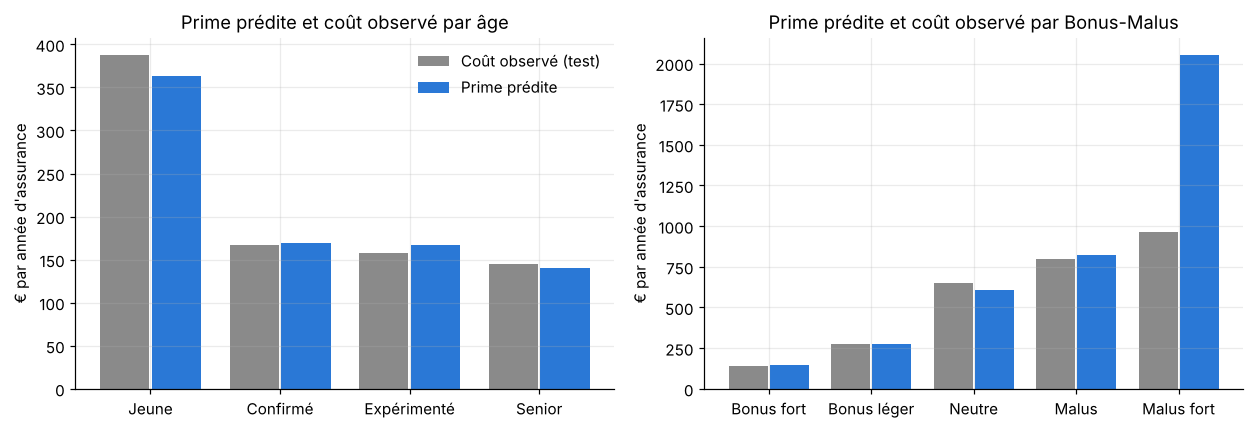

n  prime prédite / an  \
Âge         Expérimenté (41-60) 2,340.000             166.503   
            Jeune (18-25)         489.000             363.340   
            Confirmé (26-40)    1,602.000             169.518   
            Senior (61+)          764.000             140.445   
Bonus-Malus Bonus fort (50-79)  3,976.000             145.827   
            Bonus léger (80-99)   703.000             274.712   
            Neutre (100)          277.000             607.726   
            Malus (101-150)       229.000             825.645   
            Malus fort (>150)      10.000           2,054.534   

                                 coût observé / an  
Âge         Expérimenté (41-60)            157.730  
            Jeune (18-25)                  388.047  
            Confirmé (26-40)               167.356  
            Senior (61+)                   144.623  
Bonus-Malus Bonus fort (50-79)             142.278  
            Bonus léger (80-99)            277.082  
            Neutre (100)                   648.302  
            Malus (101-150)                796.206  
            Malus fort (>150)              966.329

In [13]:
def par_segment(d, var):
    g = d.groupby(var, observed=True).agg(expo=("Exposure", "sum"), predit=("prime_attendue", "sum"), observe=("cout_ecrete", "sum"), n=("nb", "sum"))
    g["prime prédite / an"] = g["predit"] / g["expo"]
    g["coût observé / an"] = g["observe"] * (1 + k) / g["expo"]
    return g

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for ax, var, ordre in [(axes[0], "age", ["Jeune (18-25)", "Confirmé (26-40)", "Expérimenté (41-60)", "Senior (61+)"]), (axes[1], "bm", BM)]:
    g = par_segment(test, var).reindex(ordre)
    x = np.arange(len(g))
    ax.bar(x - 0.2, g["coût observé / an"], width=0.38, color=GRIS, label="Coût observé (test)")
    ax.bar(x + 0.2, g["prime prédite / an"], width=0.38, color=BLEU, label="Prime prédite")
    ax.set_xticks(x, [o.split(" (")[0] for o in ordre])
    ax.set_ylabel("€ par année d'assurance")
    ax.set_title(f"Prime prédite et coût observé par {'âge' if var == 'age' else 'Bonus-Malus'}")
axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "tarif_predit_vs_observe.png", dpi=150); plt.show()

pd.concat({"Âge": par_segment(test, "age"), "Bonus-Malus": par_segment(test, "bm")})[["n", "prime prédite / an", "coût observé / an"]]

**Lecture.** Pour chaque tranche d'âge et chaque niveau de Bonus-Malus, la prime prédite est proche du coût réellement observé sur les contrats test : le tarif fait payer à chaque groupe un prix qui correspond à son risque.
La seule exception est le **malus fort** : le tarif prévoit environ 2 050 € par an contre 970 € observés, mais l'échantillon test ne contient que **10 sinistres** dans cette classe. C'est exactement le problème de crédibilité vu dans le tableau de bord : une classe aussi petite ne permet pas d'estimer un coefficient fiable.

Gini du tarif sur l'échantillon test : 0.185 (coûts écrêtés), 0.195 (coûts bruts)


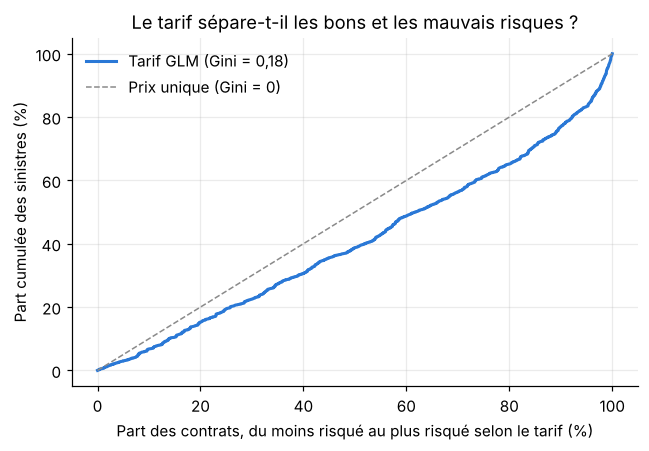

In [14]:
def lorenz(d, score, cout):
    o = d.sort_values(score)
    x = np.r_[0, o["Exposure"].cumsum() / o["Exposure"].sum()]
    y = np.r_[0, o[cout].cumsum() / o[cout].sum()]
    gini = 1 - 2 * np.trapezoid(y, x) if hasattr(np, "trapezoid") else 1 - 2 * np.trapz(y, x)
    return x, y, gini

x, y, gini = lorenz(test, "prime_pure", "cout_ecrete")
xb, yb, gini_brut = lorenz(test, "prime_pure", "cout")
print(f"Gini du tarif sur l'échantillon test : {gini:.3f} (coûts écrêtés), {gini_brut:.3f} (coûts bruts)")

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(x * 100, y * 100, color=BLEU, lw=2, label=f"Tarif GLM (Gini = {gini:.2f})".replace(".", ","))
ax.plot([0, 100], [0, 100], color=GRIS, ls="--", lw=1, label="Prix unique (Gini = 0)")
ax.set_xlabel("Part des contrats, du moins risqué au plus risqué selon le tarif (%)")
ax.set_ylabel("Part cumulée des sinistres (%)")
ax.set_title("Le tarif sépare-t-il les bons et les mauvais risques ?")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "tarif_courbe_lorenz.png", dpi=150); plt.show()

In [15]:
# Que se passerait-il avec un prix unique ? Part des contrats qui paieraient trop, et de combien en moyenne
prix_unique = test["cout_ecrete"].sum() * (1 + k) / test["Exposure"].sum()
t = test.assign(ecart=prix_unique / test["prime_pure"] - 1)
print(f"Prix unique : {prix_unique:,.0f} € par an")
print(f"Contrats qui paieraient plus que leur risque avec un prix unique : {(t['ecart'] > 0).mean():.0%} "
      f"(surcoût médian : {t.loc[t['ecart'] > 0, 'ecart'].median():.0%})")

Prix unique : 169 € par an
Contrats qui paieraient plus que leur risque avec un prix unique : 80% (surcoût médian : 12%)


## 7. Conclusions

- **Le tarif repose surtout sur la fréquence.** Le coût d'un accident varie peu d'un profil à l'autre ; seuls les nouveaux conducteurs (Bonus-Malus à 100) ont des sinistres un peu plus chers.
- **Le Bonus-Malus est le premier critère de prix**, devant l'âge et la puissance. Le coefficient d'un nouveau conducteur (100) est élevé tant qu'il n'a pas d'historique, puis le Bonus-Malus ajuste son prix année après année.
- **Le tarif est validé sur des contrats jamais vus** : les primes prédites couvrent les sinistres écrêtés, chaque segment paie un prix proche de son coût observé, et le tarif classe bien mieux les risques qu'un prix unique.
- **Avec un prix unique, la plupart des bons conducteurs paieraient trop cher** et seraient tentés de partir chez un concurrent : c'est l'antisélection que la segmentation évite.

**Limites.**
- Il s'agit d'une **prime pure** : un vrai tarif ajoute les frais de gestion, la marge et les taxes.
- Le modèle n'utilise que trois critères pour rester lisible. La région, l'âge du véhicule ou la densité de population amélioreraient le tarif, et réduiraient la surdispersion observée.
- Le seuil d'écrêtement (99,5e percentile) et le chargement sont estimés sur un seul jeu de données ; un assureur les calibrerait sur plusieurs années.
- Certains critères sont encadrés par la loi (par exemple, le sexe est interdit en Europe depuis 2012) ; ceux utilisés ici sont autorisés.